# 05 — Frozen-model distribution-shift robustness
Fit each model once on the common unshifted development sample, then evaluate the same fitted parameters across a paired severity curve. The current DGP stress jointly increases innovation scale and common correlation; isolated shift mechanisms belong in the later confirmatory study.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from innovcal.ca_rnn import DEFAULT_KL_WEIGHT_GRID, TrainingConfig
from innovcal.experiments.stress import ShiftConfig, run_shift_curve
OUT = ROOT / 'results' / 'shift'; OUT.mkdir(parents=True, exist_ok=True)

In [2]:
SEVERITIES = [0.0, 0.25, 0.5, 0.75, 1.0]
curve = run_shift_curve(
    SEVERITIES,
    config=ShiftConfig(seed=505),
    training_config=TrainingConfig(epochs=120, patience=15, seed=505),
    lambda_cal=100.0,
    sequential_weight=2000.0,
    bayesian_kl_grid=DEFAULT_KL_WEIGHT_GRID,
)
display(curve)
display(curve[['model', 'kl_weight']].dropna().drop_duplicates())
curve.to_csv(OUT / 'frozen_shift_curve.csv', index=False)

,severity,model,model_index,lambda_cal,lambda_seq,kl_weight,nll,mean_squared_error,rmse,energy_score,...,pit_mean_absolute_autocorrelation,pit_mean_ks,coordinate_pit_calibration_error,coordinate_pit_mean_absolute_autocorrelation,coordinate_pit_mean_ks,delta_nll,delta_energy_score,delta_interval_score,delta_pit_calibration_error,delta_pit_mean_absolute_autocorrelation
0,0.00,RNN,0,0.0,0.0,NaN,5.198196,0.827036,0.909415,1.202168,...,0.068001,0.057560,0.000844,0.069192,0.055770,0.000000,0.000000,0.000000,0.000000,0.000000
1,0.00,BRNN,1,0.0,0.0,1.0,5.312903,0.839557,0.916274,1.214960,...,0.064520,0.055885,0.000728,0.067570,0.059886,0.000000,0.000000,0.000000,0.000000,0.000000
2,0.00,CA-RNN,2,100.0,2000.0,NaN,5.218812,0.826609,0.909180,1.203922,...,0.073756,0.068837,0.001312,0.073440,0.068257,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.00,CA-BRNN,3,100.0,2000.0,1.0,5.388779,0.852793,0.923468,1.226840,...,0.061285,0.060291,0.000994,0.066114,0.062750,0.000000,0.000000,0.000000,0.000000,0.000000
4,0.25,RNN,0,0.0,0.0,NaN,6.023066,1.277848,1.130419,1.488607,...,0.068344,0.062786,0.001142,0.067634,0.068070,0.824870,0.286438,1.027169,0.000139,0.000343
5,0.25,BRNN,1,0.0,0.0,1.0,6.175246,1.295703,1.138289,1.500291,...,0.063631,0.062314,0.001003,0.062948,0.066199,0.862343,0.285331,0.934241,0.000209,-0.000890
6,0.25,CA-RNN,2,100.0,2000.0,NaN,5.963006,1.275724,1.129479,1.481199,...,0.073641,0.051738,0.000765,0.070193,0.057510,0.744195,0.277276,0.901135,-0.000747,-0.000116
7,0.25,CA-BRNN,3,100.0,2000.0,1.0,6.225996,1.311714,1.145301,1.507454,...,0.060951,0.059961,0.000877,0.063464,0.060348,0.837217,0.280614,0.920838,-0.000257,-0.000335
8,0.50,RNN,0,0.0,0.0,NaN,6.874994,1.821732,1.349716,1.787948,...,0.069044,0.104605,0.003485,0.067048,0.108489,1.676798,0.585780,2.533687,0.002526,0.001043
9,0.50,BRNN,1,0.0,0.0,1.0,7.051017,1.849740,1.360052,1.797756,...,0.063671,0.098536,0.003342,0.061874,0.099632,1.738114,0.582796,2.319080,0.002539,-0.000849


,model,kl_weight
1,BRNN,1.0
3,CA-BRNN,1.0


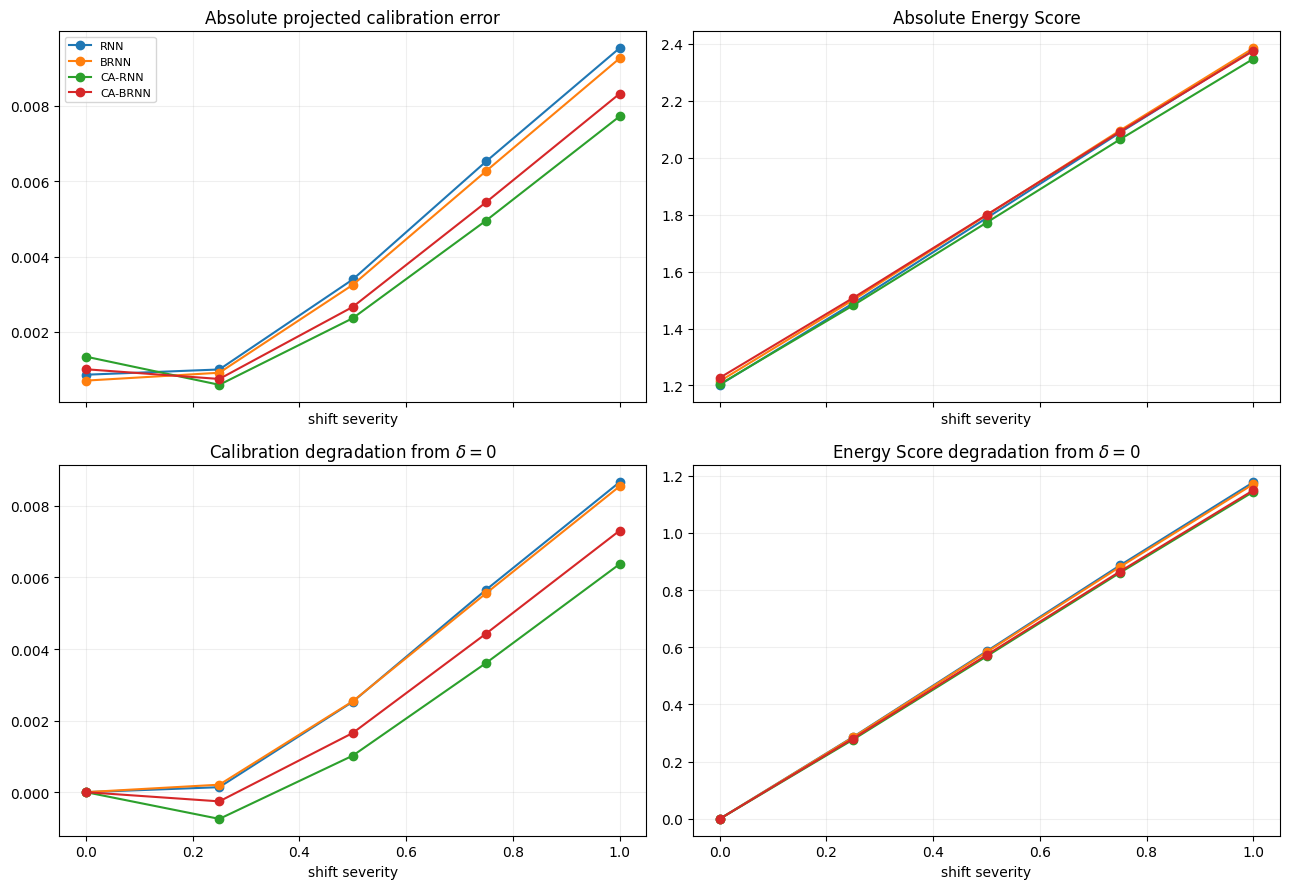

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)
for model, group in curve.groupby('model', sort=False):
    group = group.sort_values('severity')
    axes[0, 0].plot(group.severity, group.pit_calibration_error, marker='o', label=model)
    axes[0, 1].plot(group.severity, group.energy_score, marker='o', label=model)
    axes[1, 0].plot(group.severity, group.delta_pit_calibration_error, marker='o', label=model)
    axes[1, 1].plot(group.severity, group.delta_energy_score, marker='o', label=model)
axes[0, 0].set_title('Absolute projected calibration error')
axes[0, 1].set_title('Absolute Energy Score')
axes[1, 0].set_title(r'Calibration degradation from $\delta=0$')
axes[1, 1].set_title(r'Energy Score degradation from $\delta=0$')
for axis in axes.flat:
    axis.set_xlabel('shift severity')
    axis.grid(alpha=0.2)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()

In [4]:
terminal = curve.loc[curve.severity.eq(max(SEVERITIES))].copy()
display(terminal[[
    'model', 'nll', 'energy_score', 'pit_calibration_error',
    'pit_mean_absolute_autocorrelation', 'delta_energy_score',
    'delta_pit_calibration_error'
]].sort_values('pit_calibration_error'))

,model,nll,energy_score,pit_calibration_error,pit_mean_absolute_autocorrelation,delta_energy_score,delta_pit_calibration_error
18,CA-RNN,8.127048,2.347387,0.007717,0.070788,1.143465,0.006372
19,CA-BRNN,8.447115,2.375519,0.008317,0.063634,1.148679,0.007307
17,BRNN,8.593815,2.384975,0.009255,0.068254,1.170015,0.008546
16,RNN,8.400846,2.378922,0.009528,0.068007,1.176754,0.008662


## Interpretation rules
Report both absolute performance and degradation from severity zero. A model is not robust merely because it starts from worse nominal performance and therefore deteriorates less. Treat this notebook as developmental: the combined scale/dependence stress, one DGP seed, and provisional regularization weights do not support confirmatory conclusions.